# Plotting Reference
Combined plotting code from across the project for quick reference.

**Sources:**
- `DARPA/ATR object detection/uncertainty_validation.ipynb`
- `mmdet3d/uncertainty_validation.ipynb`

---
## 1. ATR — mAP vs Number of Conditions
Line plot with green/red shaded consistency regions.  
Source: `DARPA/ATR object detection/uncertainty_validation.ipynb`

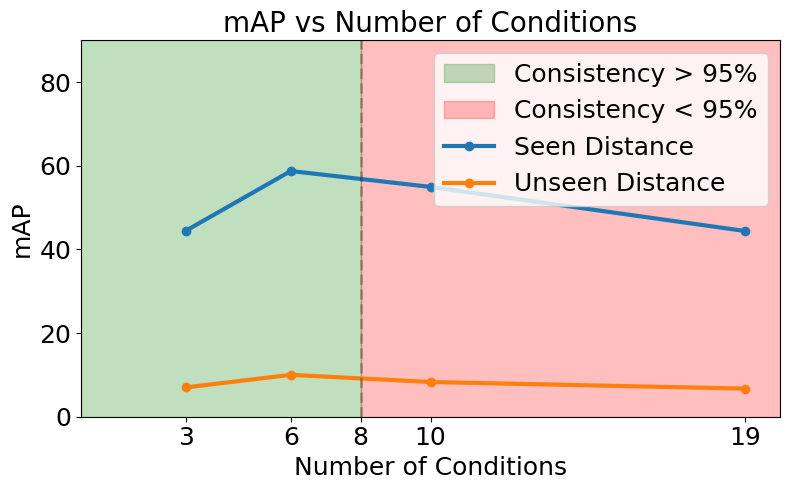

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Dictionary of test_map values vs. number of conditions
seen_map_results = {
    "3 Conditions": 44.49,
    "6 Conditions": 58.75,
    "10 Conditions": 54.95,
    "19 Conditions": 44.41,
}

unseen_map_results = {
    "3 Conditions": 7.01,
    "6 Conditions": 10.02,
    "10 Conditions": 8.3,
    "19 Conditions": 6.72,
}

# Convert to sortable form
condition_counts = [3, 6, 10, 19]
seen_map_scores = [seen_map_results[f"{count} Conditions"] for count in condition_counts]
unseen_map_scores = [unseen_map_results[f"{count} Conditions"] for count in condition_counts]

threshold = 8

fig, ax = plt.subplots(figsize=(8, 5))
x_min, x_max = 0, max(condition_counts) + 1

ax.axvspan(x_min, threshold, color='green', alpha=0.25, label='Consistency > 95%')
ax.axvspan(threshold, x_max, color='red', alpha=0.25, label='Consistency < 95%')

ax.plot(condition_counts, seen_map_scores, marker='o', label='Seen Distance', linewidth=3)
ax.plot(condition_counts, unseen_map_scores, marker='o', label='Unseen Distance', linewidth=3)

ax.axvline(threshold, color='black', alpha=0.25, linestyle='--', linewidth=2)

ax.set_title('mAP vs Number of Conditions', fontsize=20)
ax.set_xlabel('Number of Conditions', fontsize=18)
ax.set_ylabel('mAP', fontsize=18)
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xticks(condition_counts + [threshold])

ax.legend(fontsize=18)

ax.set_ylim(0.0, 90.0)
ax.set_xlim(0, max(condition_counts) + 1)

plt.tight_layout()
# plt.savefig("ATR_mAP_vs_conditions.pdf", bbox_inches='tight')
plt.show()

---
## 2. Waymo — mAP vs Number of Conditions (Day-Night & Dawn-Dusk)
Line plot with green/red shaded consistency regions.  
Source: `mmdet3d/uncertainty_validation.ipynb`

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Dictionary of test_map values vs. number of conditions
day_night_l1_map_results = {
    "3 Conditions": 28.58,
    "10 Conditions": 30.62,
    "20 Conditions": 29.20,
    "30 Conditions": 26.29,
}

dawn_dusk_l1_map_results = {
    "3 Conditions": 32.37,
    "10 Conditions": 35.2,
    "20 Conditions": 35.05,
    "30 Conditions": 31.83,
}

# Convert to sortable form
condition_counts = [3, 10, 20, 30]
day_night_map_scores = [day_night_l1_map_results[f"{count} Conditions"] for count in condition_counts]
dawn_dusk_map_scores = [dawn_dusk_l1_map_results[f"{count} Conditions"] for count in condition_counts]

threshold = 15

fig, ax = plt.subplots(figsize=(8, 5))
x_min, x_max = 0, max(condition_counts) + 1

ax.axvspan(x_min, threshold, color='green', alpha=0.25, label='Consistency > 95%')
ax.axvspan(threshold, x_max, color='red', alpha=0.25, label='Consistency < 95%')

ax.plot(condition_counts, day_night_map_scores, marker='o', label='Day-Night', linewidth=3)
ax.plot(condition_counts, dawn_dusk_map_scores, marker='o', label='Dawn-Dusk', linewidth=3)

ax.axvline(threshold, color='black', alpha=0.25, linestyle='--', linewidth=2)

ax.set_title('mAP vs Number of Conditions', fontsize=20)
ax.set_xlabel('Number of Conditions', fontsize=18)
ax.set_ylabel('mAP', fontsize=18)
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xticks(condition_counts + [threshold])

ax.legend(fontsize=18)

ax.set_ylim(20.0, 50.0)
ax.set_xlim(0, max(condition_counts) + 1)

plt.tight_layout()
plt.savefig("Waymo_mAP_vs_conditions.pdf", bbox_inches='tight')
plt.show()

---
## 3. Waymo — Grouped Bar Chart: VLM Comparison (GPT-4o / Moondream2 / SmolVLM)
Grouped bar chart comparing 3D mAP scores across Day-Night and Dawn/Dusk scenarios.  
Source: `mmdet3d/uncertainty_validation.ipynb`

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# mAP scores
map_scores = {
    "GPT-4o (baseline)": {"Day-Night": 30.62, "Dawn/dusk": 35.19},
    "Moondream2": {"Day-Night": 30.14, "Dawn/dusk": 33.91},
    "SmolVLM":    {"Day-Night": 27.31,  "Dawn/dusk": 30.22},
}

models     = list(map_scores.keys())
variations = list(next(iter(map_scores.values())).keys())

# Chart params
width      = 0.1
inner_gap  = 0.01
outer_gap  = 0.3
colors     = ["#4C72B0", "forestgreen", "purple"]

n_models   = len(models)
group_width = n_models*width + (n_models-1)*inner_gap
centers    = np.arange(len(variations)) * (group_width + outer_gap)

fig, ax = plt.subplots(figsize=(8, 5))
all_bars = []

for i, model in enumerate(models):
    heights = [map_scores[model][v] for v in variations]
    offset  = i*(width+inner_gap) - (group_width - width)/2
    positions = centers + offset

    bars = ax.bar(
        positions, heights,
        width=width,
        color=colors[i],
        label=model,
        alpha=0.7 if i != 0 else 1,
        hatch='/' if i == 0 else None,
    )
    all_bars.append(bars)

# annotate each bar with its height
for bars in all_bars:
    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=16
    )

# styling
ax.set_xticks(centers)
ax.set_xticklabels(variations)
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_ylabel("3D mAP Score", fontsize=20)
ax.set_xlabel("Scenarios", fontsize=20)
ax.set_ylim(0, 38)
ax.legend(fontsize=18, loc='lower center')

plt.tight_layout()
plt.savefig("Waymo_small_vlms.pdf", bbox_inches='tight')
plt.show()

---
## Note: Radar / Spider Plot
No radar or spider plot was found anywhere in the project. If one existed in another session or tool, it may not have been saved to this directory.